In [1]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import CCA
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
import jax
import jax.numpy as jnp
import optax


from utils import read_utils
from utils import plot_utils
from utils import train_utils

sys.path.append(os.path.join(os.getcwd(), '../../'))
from models import bom
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/../../models/hgm.py'>

# data

In [3]:
selection_n = 5
selection_bhl = ['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']

# read_ids = list(range(0, 12+1))
read_ids = [0, 2, 3, 8, 9]
plot_id = 0

dims = 2

In [4]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

filename = filenames[file_ids.index(plot_id)]
traces = traces[file_ids.index(plot_id)]
markers = markers[file_ids.index(plot_id)]
states = states[file_ids.index(plot_id)]

In [5]:
# prep

traces = pd.DataFrame(data=traces.values - np.median(traces.values, axis=0), columns=traces.columns)

# sklearn CCA

In [6]:
X = traces.values
Y = states[selection_bhl].values

In [7]:
cca = CCA(n_components=dims, scale=True)
cca.fit(X, Y)
X_l_h, Y_l_h = cca.transform(X, Y)
X_rec_h, Y_rec_h = cca.inverse_transform(X_l_h, Y_l_h)

# def norm_temp(X_proj):
# 	X_proj = X_proj - np.mean(X_proj, axis=0)
# 	X_proj = X_proj / (np.linalg.norm(X_proj, axis=0) + 1e-6)
# 	return X_proj
# corr_a = np.array(norm_temp(X_l_h).T @ norm_temp(Y_l_h))


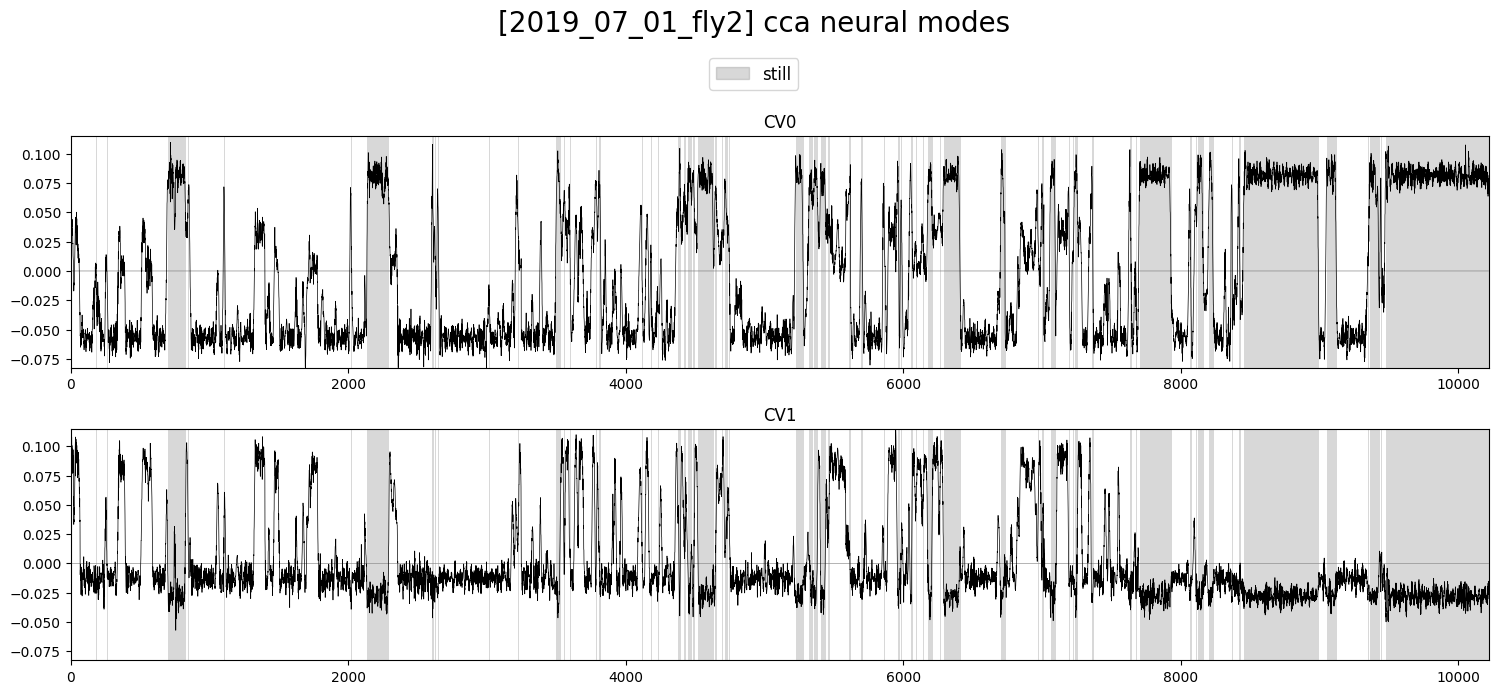

In [8]:
X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'CV{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca neural modes',
					   states[['still']],
					   [X_l_h_df],
					   plots_per_row=1, ylimits=None)

In [9]:
Y_l_h_df = pd.DataFrame(data=Y_l_h, columns=[f'CV{i}' for i in range(dims)])

# plot_utils.plot_traces(f'[{filename}] cca behavioral modes',
# 					   states[['still']],
# 					   [Y_l_h_df],
# 					   plots_per_row=1, ylimits=None)

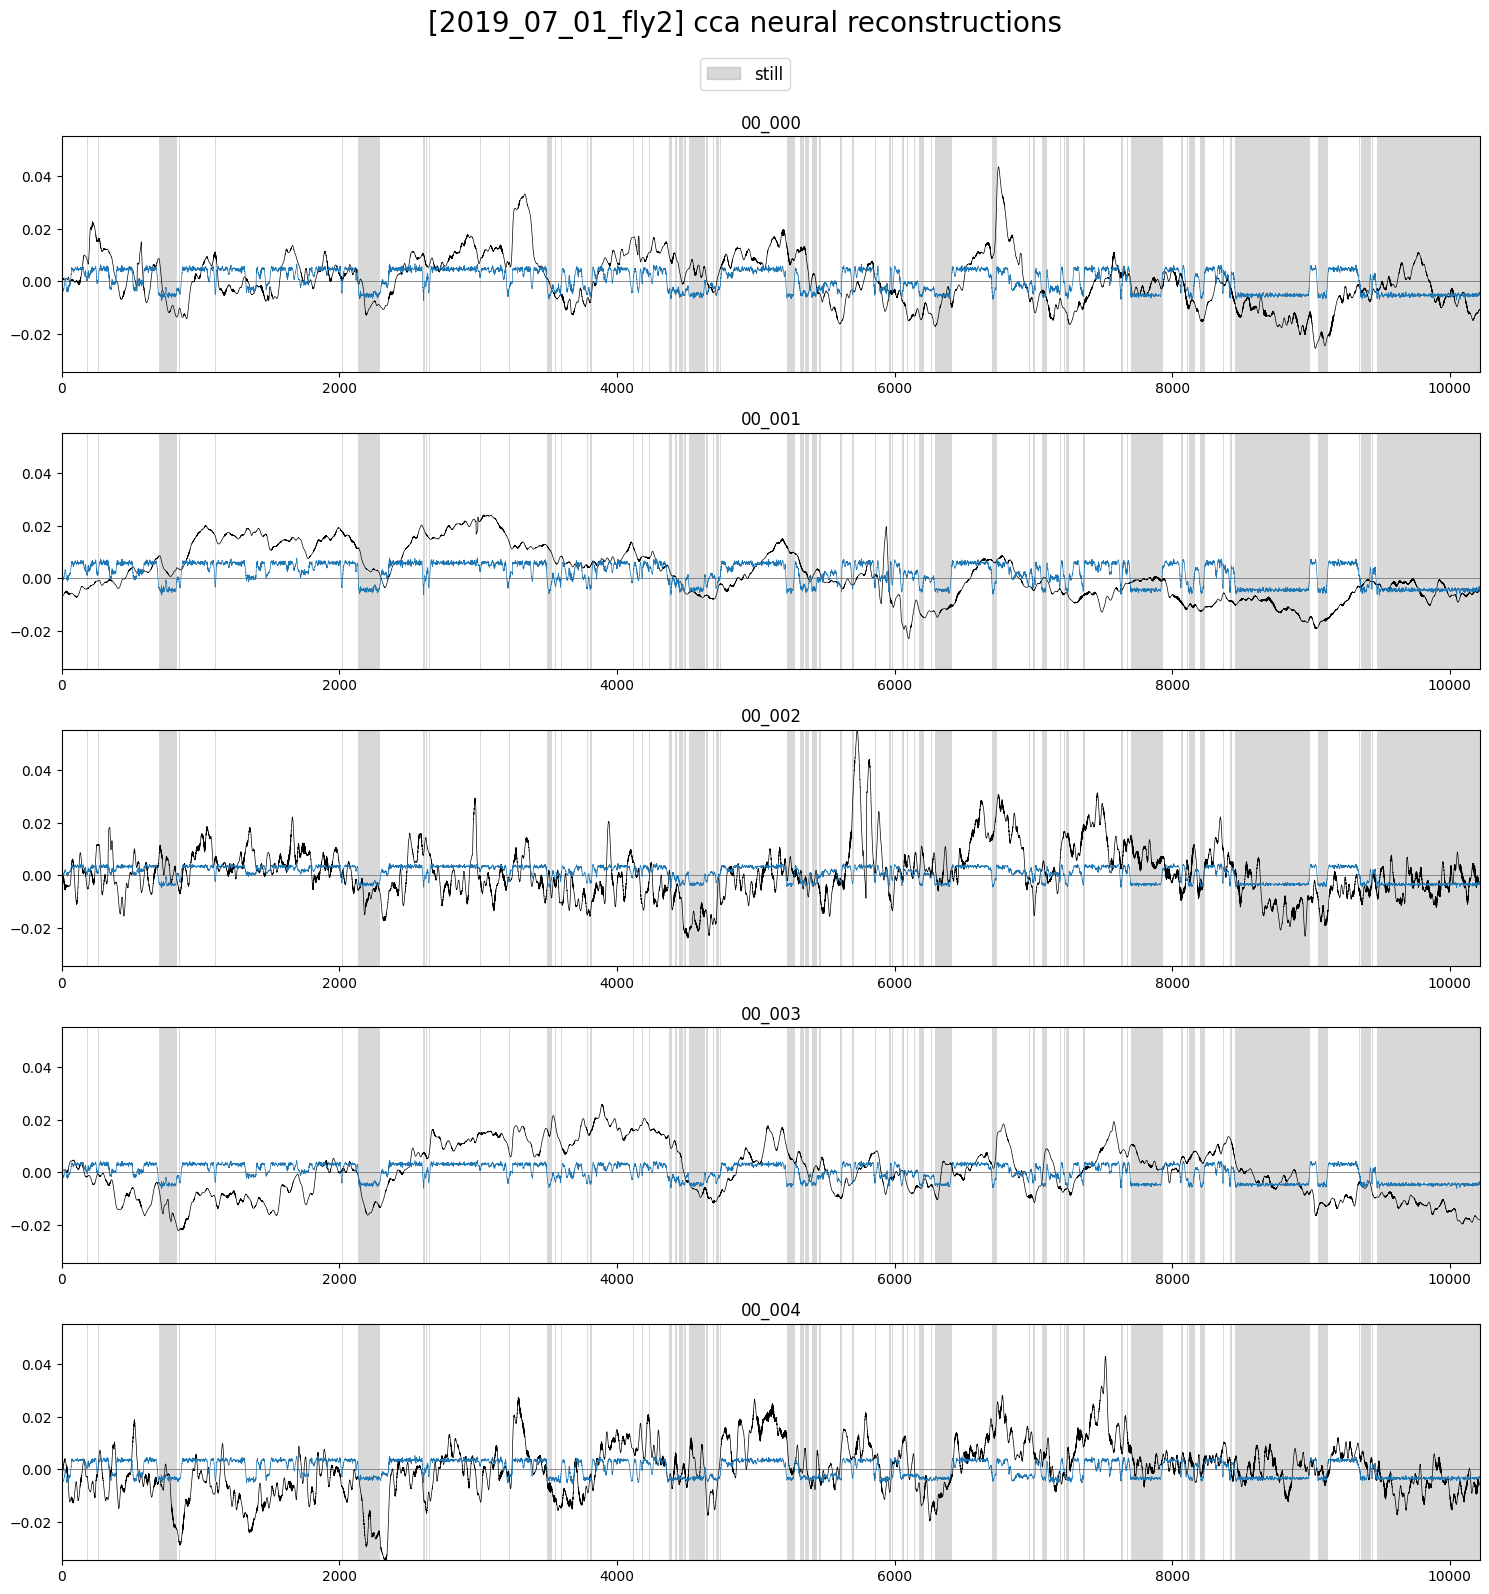

In [10]:
X_rec_h_df = pd.DataFrame(data=X_rec_h, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca neural reconstructions',
					   states[['still']],
					   [traces.iloc[:, :selection_n], X_rec_h_df.iloc[:, :selection_n]],
					   plots_per_row=1, ylimits=None)

In [11]:
Y_rec_h_df = pd.DataFrame(data=Y_rec_h, columns=states[selection_bhl].columns)

# plot_utils.plot_traces(f'[{filename}] cca behavioral reconstructions',
# 					   states[['still']],
# 					   [states, Y_rec_h_df],
# 					   plots_per_row=1, ylimits=None)

# soft CCA

In [12]:
class Lambdas(NamedTuple):
	cca_lambdas: tuple[float, float]


def init_params(N, B_hl, seeds, shape_U, shape_V):
	return {
		'prep': {
			'N': {
				'mean': N.mean(axis=0),
				'std': jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std),
			},
			'B_hl': {
				'mean': B_hl.mean(axis=0),
				'std': jnp.where((B_hl_std := jnp.std(B_hl, axis=0)) == 0.0, 1.0, B_hl_std),
			},
		},
		'model': {
			'U': 1E-2 * jax.random.normal(seeds[0], shape_U),
			'V': 1E-2 * jax.random.normal(seeds[1], shape_V)
		}
	}


#@jax.jit
def norm(X_proj):
	X_proj = X_proj - jnp.mean(X_proj, axis=0)
	X_proj = X_proj / (jnp.linalg.norm(X_proj, axis=0) + 1e-6)
	return X_proj

@jax.jit
def cca_loss(X_proj, Y_proj, ccadiag_lambda, ccaunit_lambda):
	corr = norm(X_proj).T @ norm(Y_proj)

	corr_diag = jnp.diag(jnp.diag(corr))
	corr_nondiag = corr - corr_diag

	return (ccadiag_lambda * jnp.mean(jnp.abs(corr_nondiag))
			+ ccaunit_lambda * jnp.mean(jnp.abs(corr_diag - jnp.eye(*corr_diag.shape))))

#@jax.jit
def loss_fn(params, N, B_hl, lambdas):
	ccadiag_lambda, ccaunit_lambda = lambdas.cca_lambdas

	# manifold ======================================
	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	prep_b_hl = jax.lax.stop_gradient(params['prep']['B_hl'])

	N_mean, N_std = prep_n['mean'], prep_n['std']
	B_hl_mean, B_hl_std = prep_b_hl['mean'], prep_b_hl['std']

	U = params['model']['U']
	V = params['model']['V']

	N_zs = (N - N_mean) / N_std
	B_hl_zs = (B_hl - B_hl_mean) / B_hl_std

	N_man = N_zs @ U
	B_hl_man = B_hl_zs @ V

	man_loss = cca_loss(N_man, B_hl_man, ccadiag_lambda, ccaunit_lambda)
	# ===============================================

	return man_loss

loss_and_grads = jax.jit(jax.value_and_grad(loss_fn, has_aux=False), static_argnums=(3,))


def update(opt_update, opt_state, params, N, B_hl, lambdas):
	loss, grads = loss_and_grads(params, N, B_hl, lambdas)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return opt_state, params_new, loss

In [13]:
def soft_cca_train(N, B_hl, hyperparams):
	max_epochs = hyperparams['max_epochs']
	n_dimensions = hyperparams['dimensions']
	learning_rate = hyperparams['learning_rate']
	lambdas = Lambdas(cca_lambdas=(hyperparams['ccadiag_lambda'], hyperparams['ccaunit_lambda']))

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)

	params = init_params(N, B_hl, seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions))
	optimizer = optax.adam(learning_rate)
	optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
	opt_state = optimizer.init(params)

	losses_train = []
	for epoch in range(max_epochs):
		opt_state, params, loss_train = update(optimizer.update, opt_state, params, N, B_hl, lambdas)
		losses_train.append(loss_train)

	return params, losses_train


def soft_cca_predict(params, N, B_hl):

	def get_reconstruction_matrix_x(X, X_proj):
		# magic (actually just analytical least-squares solution to reconstruction)
		return np.linalg.inv(X_proj.T @ X_proj) @ X_proj.T @ X
		# return np.linalg.inv(U.T @ U) @ U.T
		# return sp.linalg.pinv(U)

	def get_reconstruction_matrix_y(Y, Y_proj):
		# magic (actually just analytical least-squares solution to reconstruction)
		return np.linalg.inv(Y_proj.T @ Y_proj) @ Y_proj.T @ Y
		# return np.linalg.inv(V.T @ V) @ V.T
		# return sp.linalg.pinv(V)

	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	prep_b_hl = jax.lax.stop_gradient(params['prep']['B_hl'])

	N_mean, N_std = prep_n['mean'], prep_n['std']
	B_hl_mean, B_hl_std = prep_b_hl['mean'], prep_b_hl['std']

	U = params['model']['U']
	V = params['model']['V']

	N_zs = (N - N_mean) / N_std
	B_hl_zs = (B_hl - B_hl_mean) / B_hl_std

	N_man = N_zs @ U
	B_hl_man = B_hl_zs @ V

	N_zs_rec = N_man @ get_reconstruction_matrix_x(N_zs, N_man)
	B_hl_zs_rec = B_hl_man @ get_reconstruction_matrix_y(B_hl_zs, B_hl_man)

	N_rec = N_zs_rec * N_std + N_mean
	B_hl_rec = B_hl_zs_rec * B_hl_std + B_hl_mean

	return np.array(N_man), np.array(B_hl_man), np.array(N_rec), np.array(B_hl_rec)

In [14]:
hyperparameters = {
	'max_epochs': 5000,
	'learning_rate': 1E-1,
	'ccadiag_lambda': 0.6,
	'ccaunit_lambda': 1.0 - 0.6,
	'dimensions': dims
}
params, losses_train = soft_cca_train(X, Y, hyperparameters)
X_l_s, Y_l_s, X_rec_s, Y_rec_s = soft_cca_predict(params, X, Y)

# corr_n = np.array(norming(X_l_s).T @ norming(Y_l_s) / norming(X_l_s).shape[0])

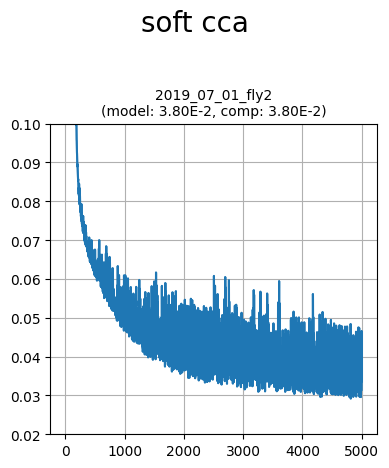

In [15]:
losses = np.array(losses_train)
plot_utils.plot_losses_splits('soft cca', [filename], [np.array([losses])], [np.array([losses])],
							  plots_per_row=1, ylimits=(losses.min(), losses.min() + (losses.max() - losses.min()) * 0.2))

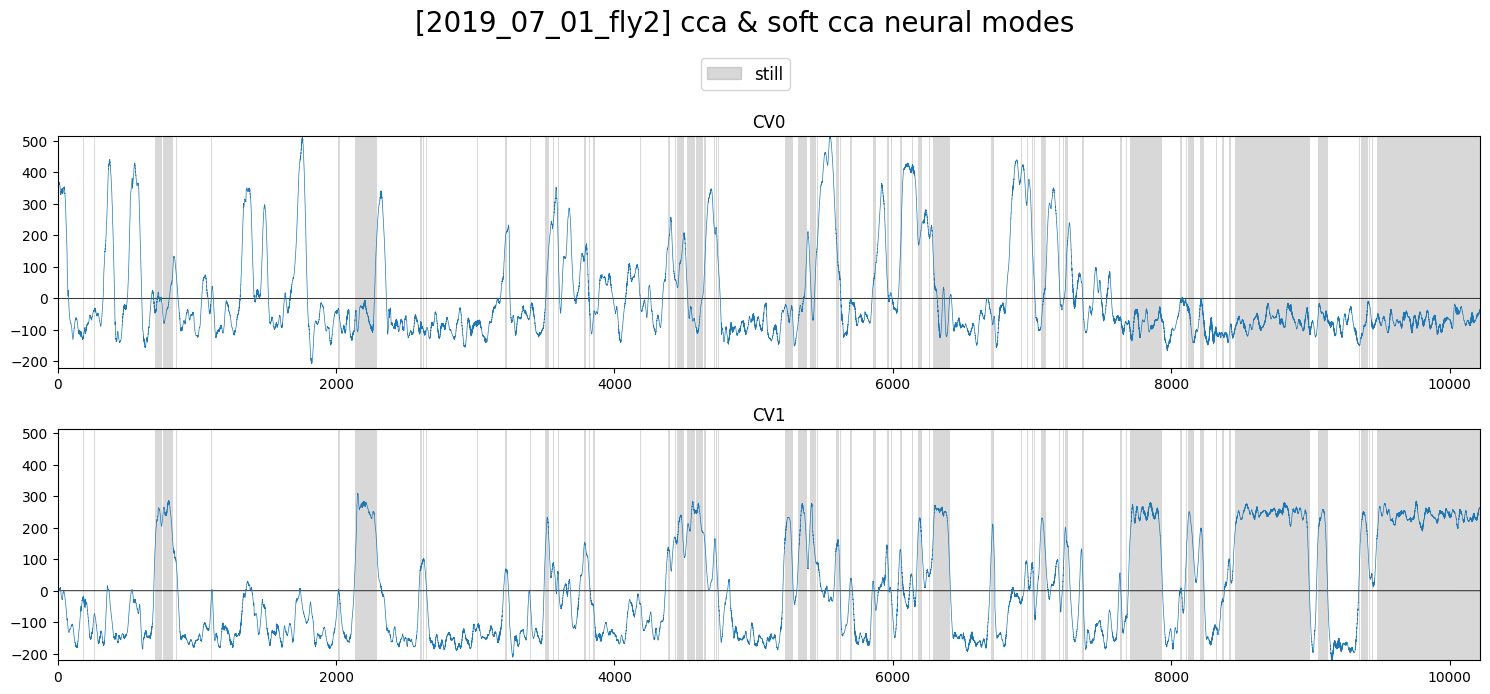

In [16]:
X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'CV{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca & soft cca neural modes',
					   states[['still']],
					   [X_l_h_df, X_l_s_df],
					   plots_per_row=1, ylimits=None)

In [17]:
Y_l_s_df = pd.DataFrame(data=Y_l_s, columns=[f'CV{i}' for i in range(dims)])

# plot_utils.plot_traces(f'[{filename}] cca & soft cca behavioral modes',
# 					   states[['still']],
# 					   [Y_l_h_df, Y_l_s_df],
# 					   plots_per_row=1, ylimits=None)

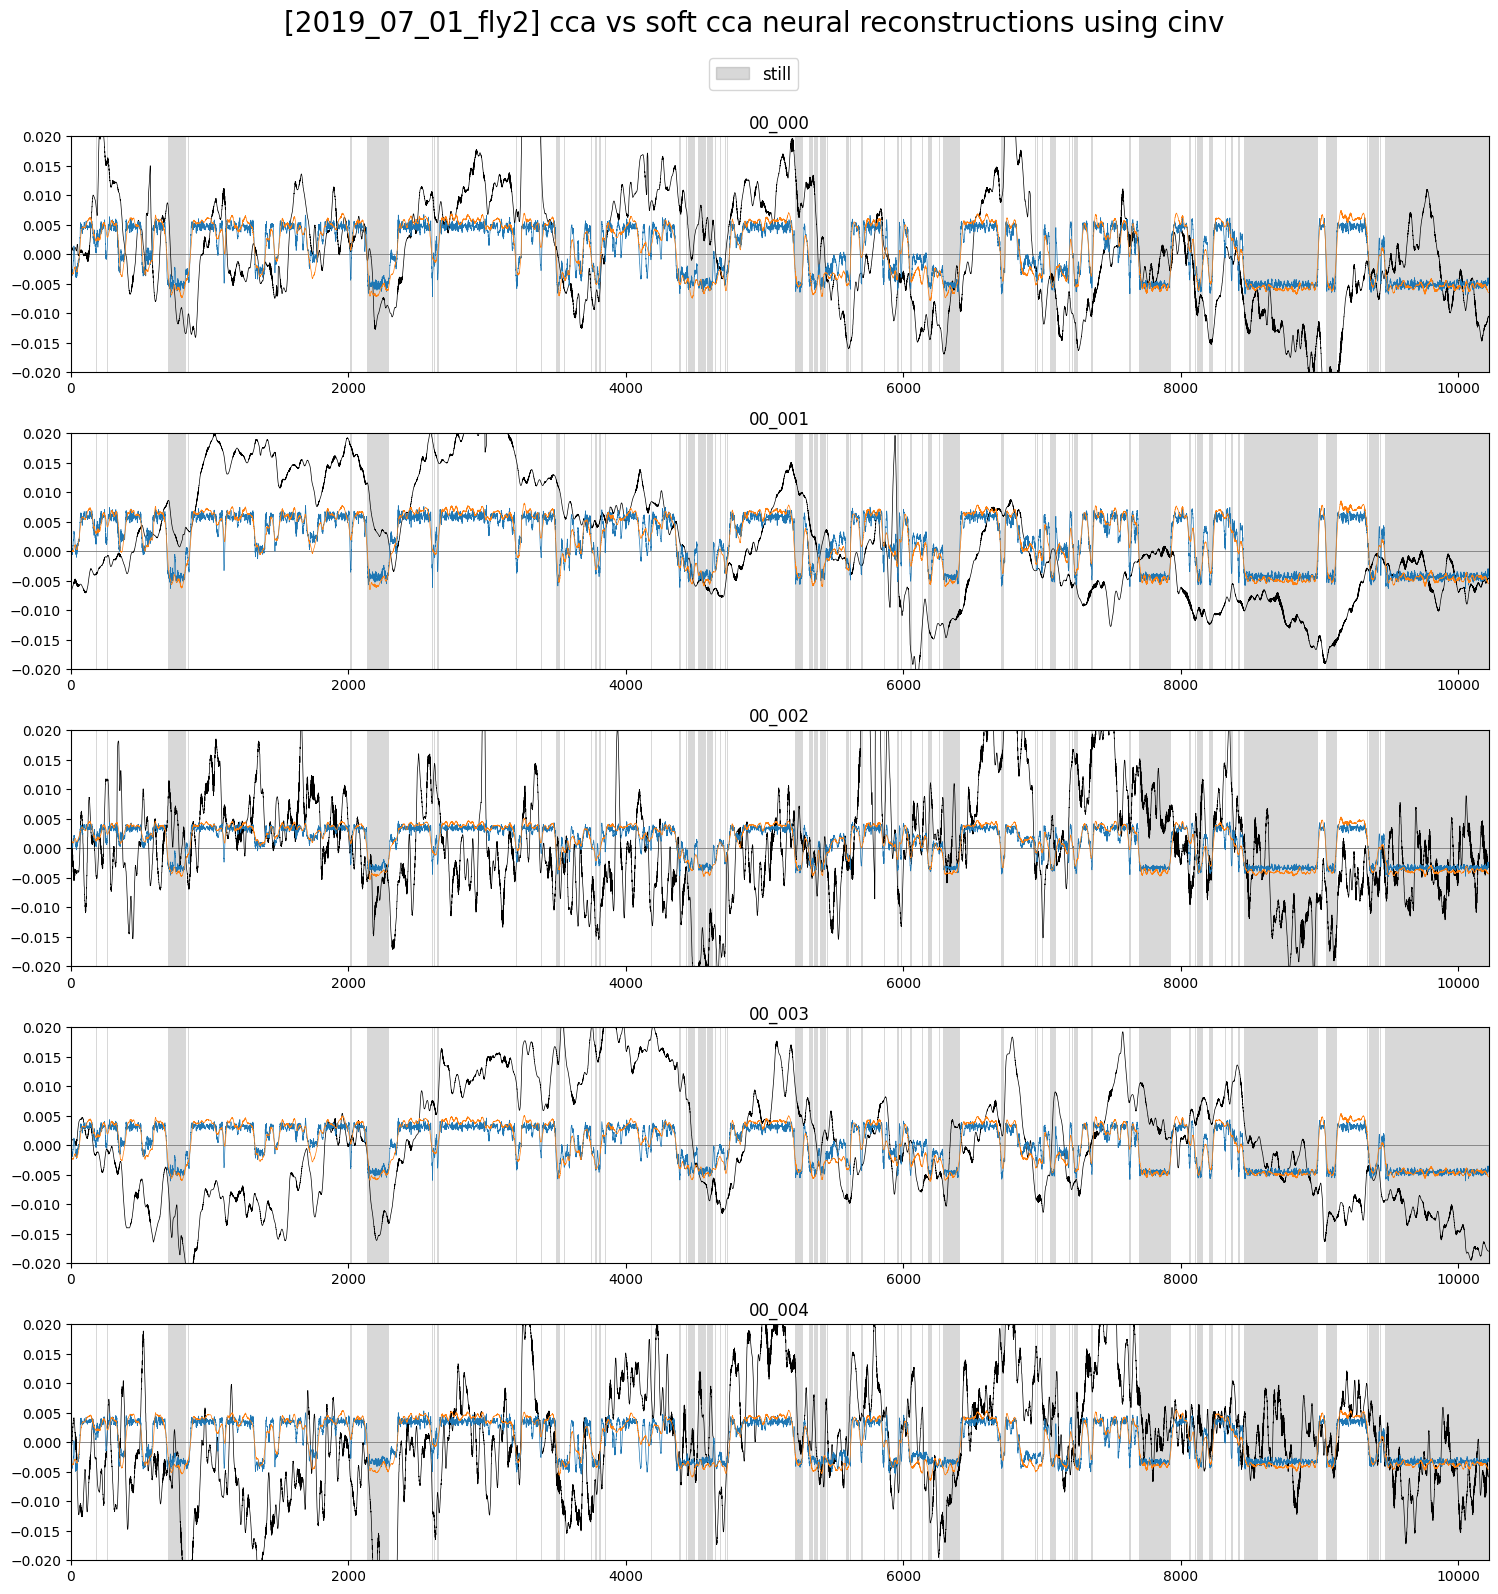

In [22]:
X_rec_s_df = pd.DataFrame(data=X_rec_s, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural reconstructions using cinv',
					   states[['still']],
					   [traces.iloc[:, :selection_n], X_rec_h_df.iloc[:, :selection_n], X_rec_s_df.iloc[:, :selection_n]],
					   plots_per_row=1, ylimits=(-0.02, 0.02))

In [19]:
Y_rec_s_cinv_df = pd.DataFrame(data=Y_rec_s, columns=states[selection_bhl].columns)

# plot_utils.plot_traces(f'[{filename}] cca vs soft cca behavioral reconstructions using cinv',
# 					   states[['still']],
# 					   [states, Y_rec_h_df, Y_rec_s_cinv_df],
# 					   plots_per_row=1, ylimits=None)

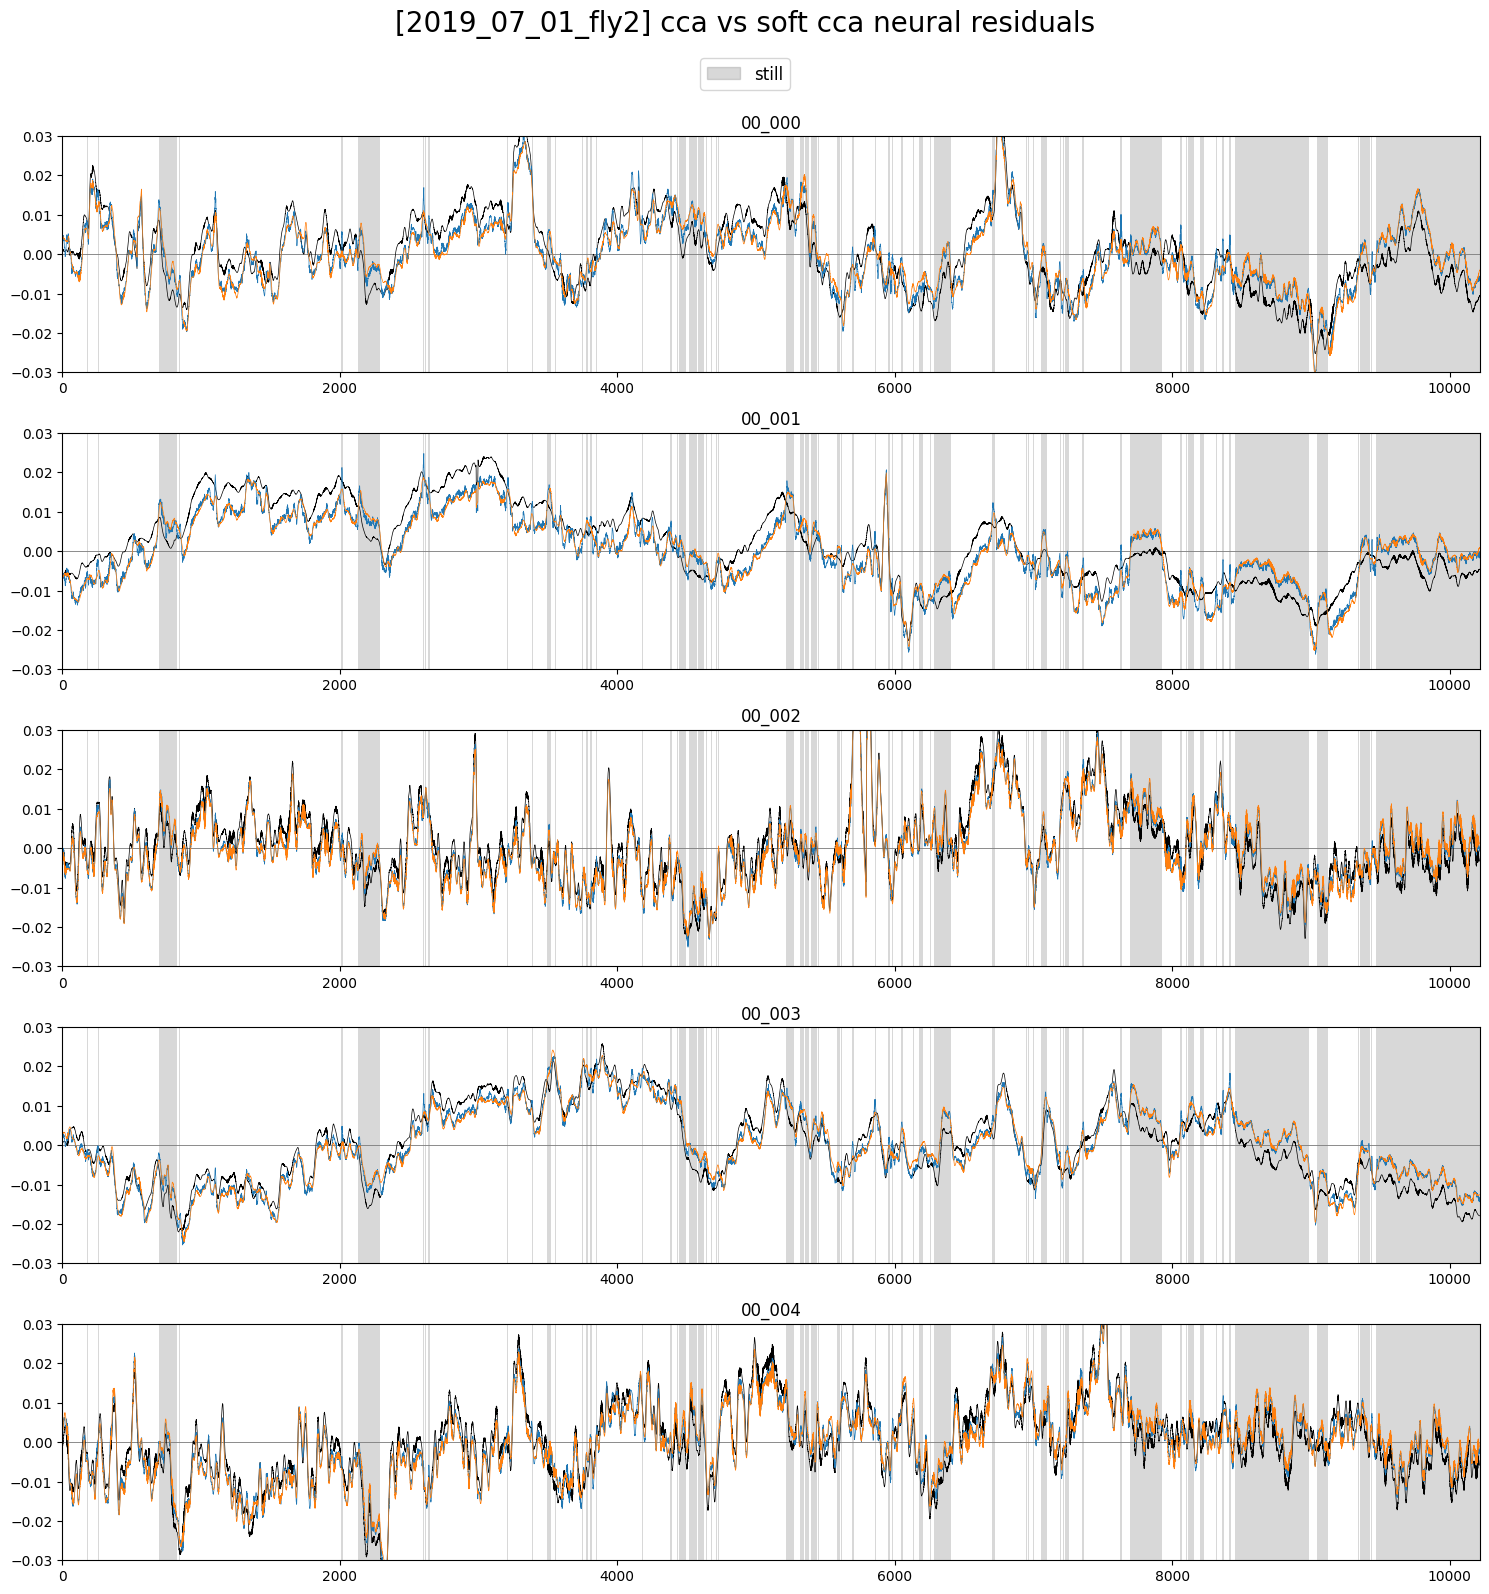

In [23]:
X_res_h_df = pd.DataFrame(data=X - X_rec_h, columns=traces.columns)
X_res_s_df = pd.DataFrame(data=X - X_rec_s, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural residuals',
					   states[['still']],
					   [traces.iloc[:, :selection_n], X_res_h_df.iloc[:, :selection_n], X_res_s_df.iloc[:, :selection_n]],
					   plots_per_row=1, ylimits=(-0.03, 0.03))

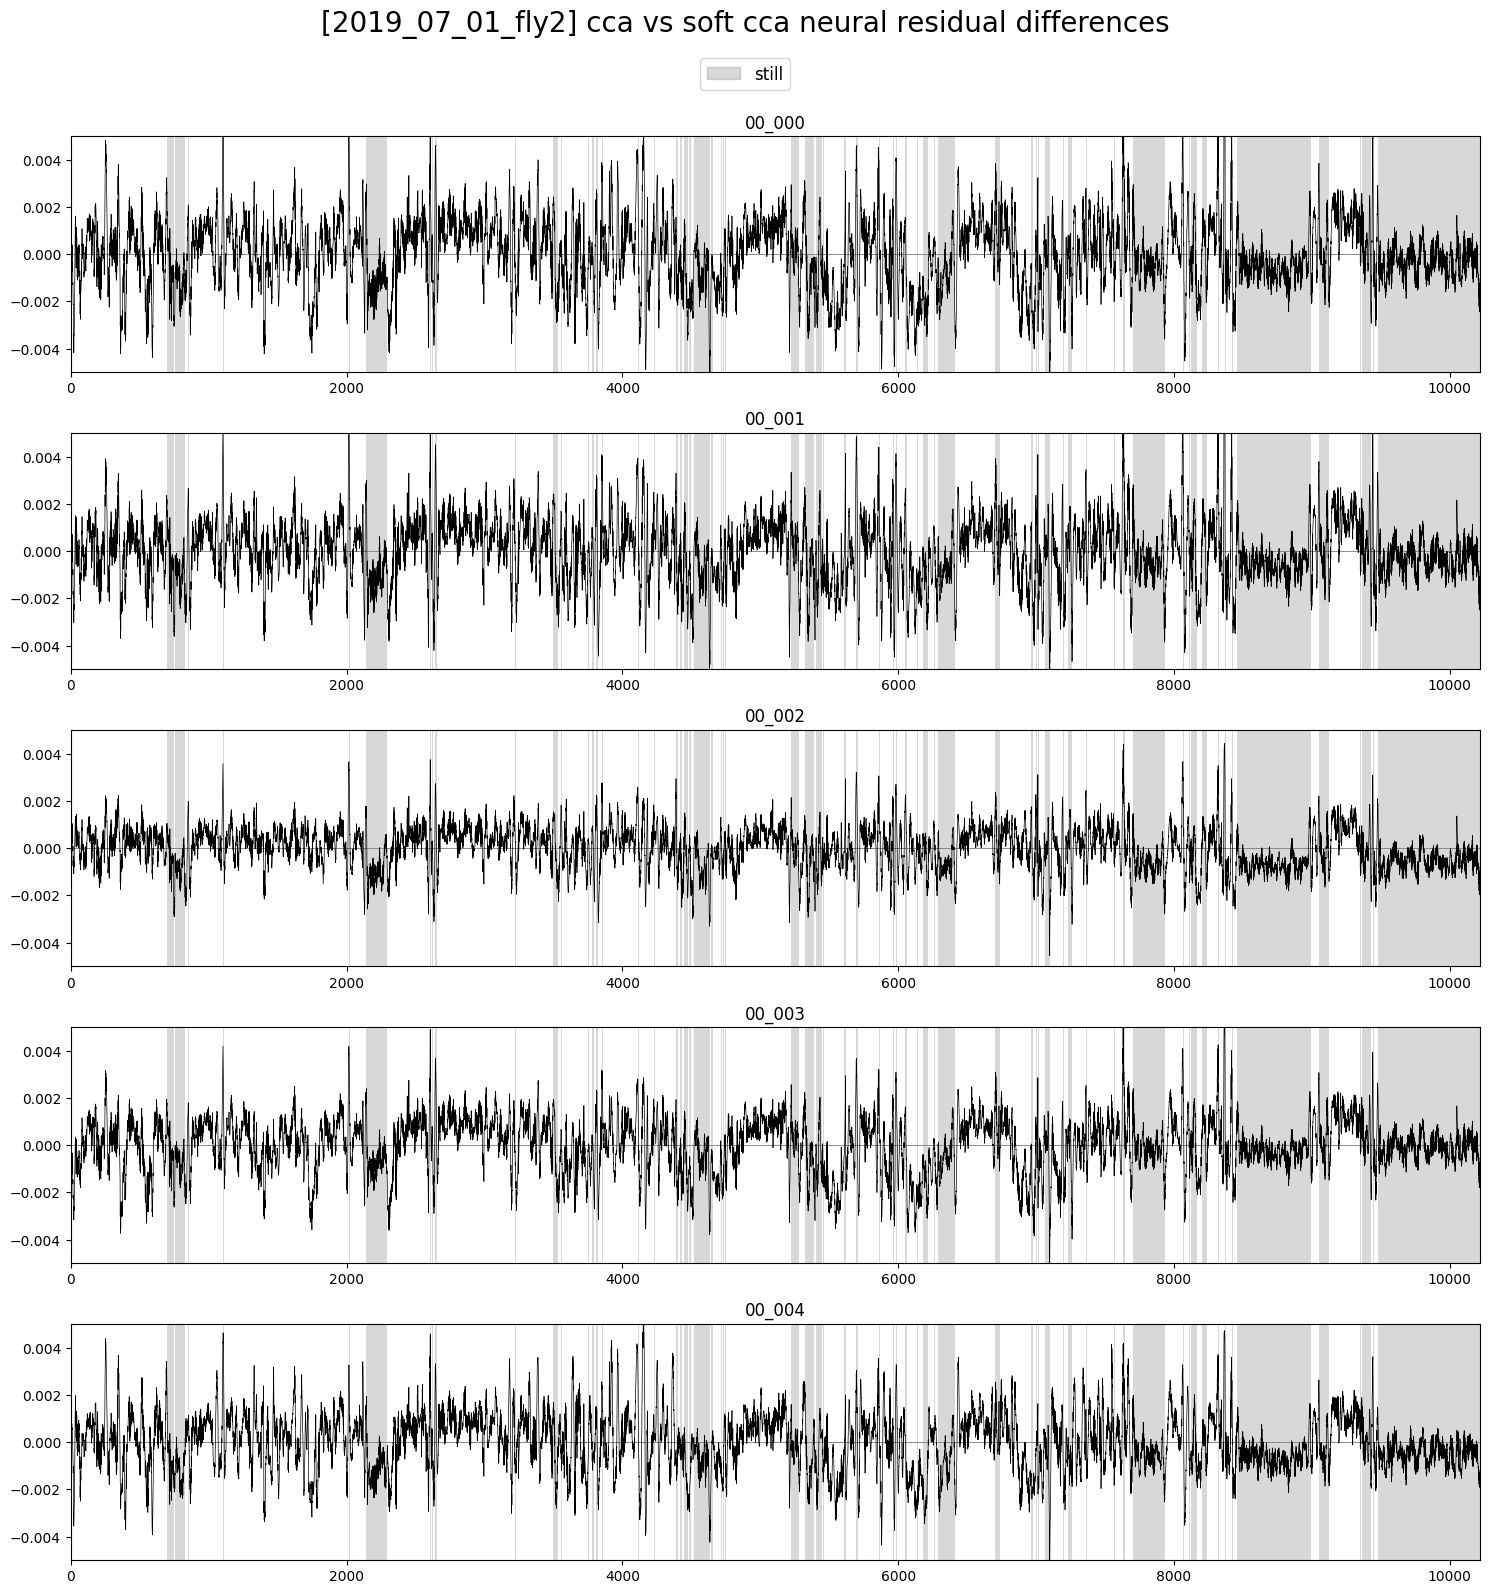

In [21]:
plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural residual differences',
					   states[['still']],
					   [X_res_h_df.iloc[:, :selection_n] - X_res_s_df.iloc[:, :selection_n]],
					   plots_per_row=1, ylimits=(-0.005, 0.005))